In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/w45_jpg.rf.0ae39f7b979002e9c0f460e8d46dd48a.jpg
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/w47_jpg.rf.7337d0fda8ccb110e234c175189ddac3.jpg
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-4-_jpg.rf.a6669711289fc117e520e0fddd152266.jpg
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-9-_jpg.rf.461647d46bd848de11e24d70bd6a06fa.jpg
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/w37_jpg.rf.1b3f039c45732a7a38ab87d2e5530b05.jpg
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/w24_jp

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(f"\nFolder: {dirname}")
    print(f"Number of files: {len(filenames)}")
    print("First 10 files:")
    
    for filename in filenames[:10]:
        print("  ", filename)


Folder: /kaggle/input
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/shijo96john
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset
Number of files: 0
First 10 files:

Folder: /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads
Number of files: 300
First 10 files:
   w45_jpg.rf.0ae39f7b979002e9c0f460e8d46dd48a.jpg
   w47_jpg.rf.7337d0fda8ccb110e234c175189ddac3.jpg
   white_head_-4-_jpg.rf.a6669711289fc117e520e0fddd152266.jpg
   white_head_-9-_jpg.rf.461647d46bd848de11e24d70bd6a06fa.jpg
   w37_jpg.rf.1b3f039c45732a7a38ab87d2e5530b05.jpg
   w24_jpg.rf.9e01ce5cf0af6b58ce4a51ef5b6cedd0.jpg
   w51_jpg.rf.e7ac819b23d63b3acdc473d42e2751

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import random

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

classes = [folder for folder in DATASET_DIR.iterdir() if folder.is_dir()]

print("Classes:")
for folder in classes:
    print(folder.name)

Classes:
non inflammatory acne white heads
Redness
dark spots
wrinkles
pores
pigmentation
inflammatory acne
non inflammatory acne black heads


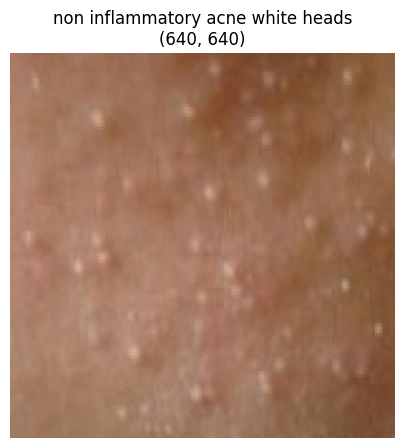

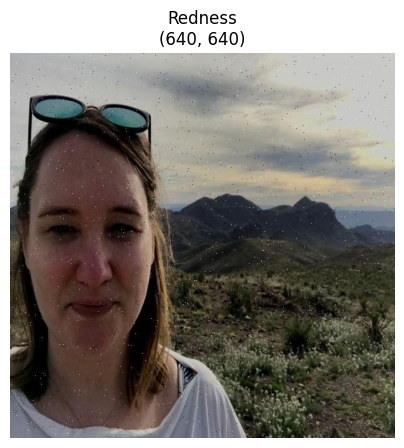

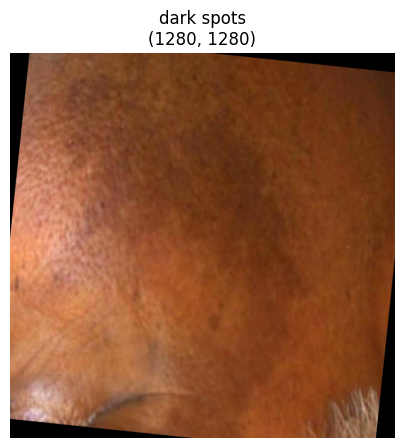

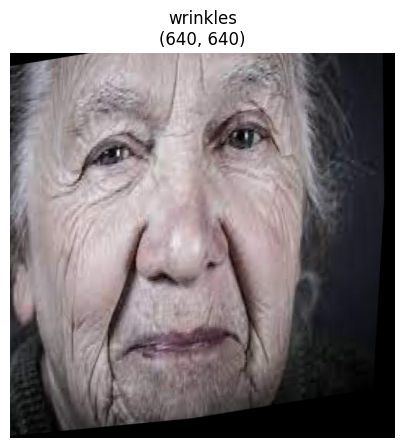

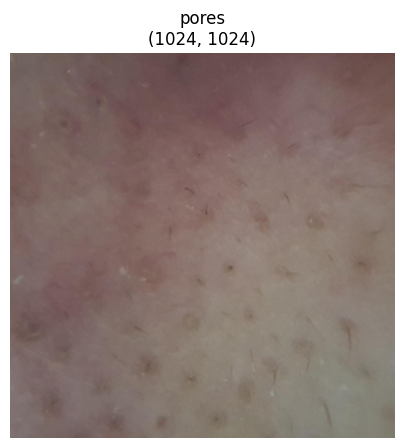

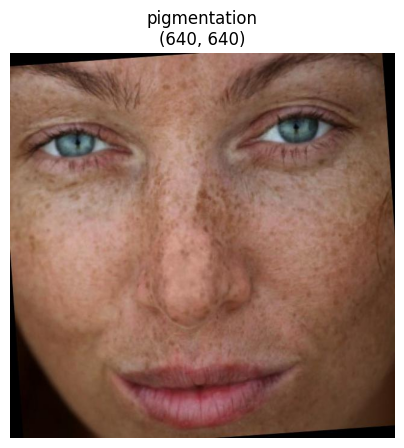

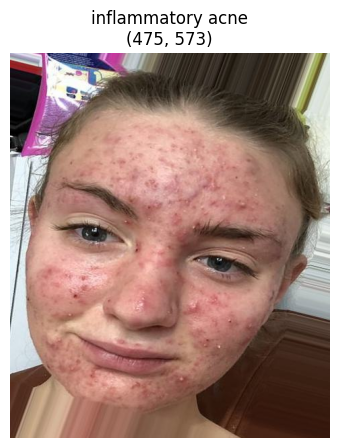

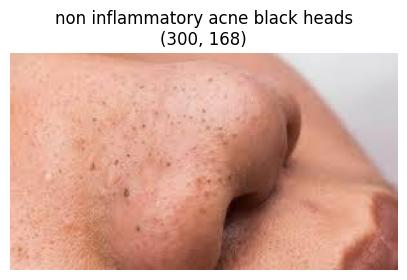

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# Dataset location
DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

# Select 1 random image from each class
for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    images = [
        f for f in class_dir.iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    image_path = random.choice(images)

    image = Image.open(image_path)

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f"{class_dir.name}\n{image.size}")
    plt.axis("off")
    plt.show()

In [5]:
from pathlib import Path
from PIL import Image
import pandas as pd

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

records = []

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:
                width, height = img.size

            records.append({
                "class": class_dir.name,
                "filename": image_path.name,
                "width": width,
                "height": height,
                "format": image_path.suffix.lower()
            })

        except Exception as e:
            print("Could not read:", image_path)

df = pd.DataFrame(records)

print("Total images:", len(df))
print("\nImages per class:")
print(df["class"].value_counts())

print("\nImage dimensions:")
print(df[["width", "height"]].describe())

Total images: 4233

Images per class:
class
dark spots                           619
inflammatory acne                    603
wrinkles                             600
Redness                              600
pores                                600
pigmentation                         599
non inflammatory acne black heads    312
non inflammatory acne white heads    300
Name: count, dtype: int64

Image dimensions:
             width       height
count  4233.000000  4233.000000
mean    710.324592   693.831325
std     317.381018   336.189870
min     150.000000   149.000000
25%     640.000000   640.000000
50%     640.000000   640.000000
75%     640.000000   640.000000
max    6900.000000  5312.000000


In [6]:
from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

all_files = []
image_files = []

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for file in class_dir.iterdir():
        all_files.append(file)

        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_files.append(file)

print("Total files:", len(all_files))
print("Image files:", len(image_files))
print("Non-image files:", len(all_files) - len(image_files))

print("\nNon-image files:")
for file in all_files:
    if file.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        print(file)

Total files: 4235
Image files: 4233
Non-image files: 2

Non-image files:
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/pigmentation/_classes.csv
/kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne black heads/desktop.ini


In [7]:
from pathlib import Path
from PIL import Image

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

valid_images = []
corrupted_images = []

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            valid_images.append(image_path)

        except Exception as e:
            corrupted_images.append((image_path, str(e)))

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted files:")
    for path, error in corrupted_images:
        print(path)
        print("Reason:", error)

Valid images: 4233
Corrupted images: 0


In [8]:
from pathlib import Path
from hashlib import md5
from collections import defaultdict

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

hash_to_files = defaultdict(list)

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        with open(image_path, "rb") as f:
            file_hash = md5(f.read()).hexdigest()

        hash_to_files[file_hash].append(image_path)

duplicate_groups = {
    h: files
    for h, files in hash_to_files.items()
    if len(files) > 1
}

print("Total images:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))

duplicate_image_count = sum(
    len(files) for files in duplicate_groups.values()
)

print("Images involved in duplicates:", duplicate_image_count)

if duplicate_groups:
    print("\nDuplicate examples:")

    for i, (file_hash, files) in enumerate(duplicate_groups.items()):
        print(f"\nGroup {i + 1}:")
        for file in files:
            print(" ", file)

        if i >= 9:
            break

Total images: 4101
Duplicate groups: 113
Images involved in duplicates: 245

Duplicate examples:

Group 1:
  /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-5-_jpg.rf.d24fc57254bc1535cf458f2d01ebcaed.jpg
  /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-5-_jpg.rf.ec270a4f18c9504b16c284ce873a7281.jpg

Group 2:
  /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-5-_jpg.rf.4416e9a98c22e2750f709b6f0cc7a777.jpg
  /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-5-_jpg.rf.f4fd7260dddd07b29fe1384eedcffa99.jpg

Group 3:
  /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/non inflammatory acne white heads/white_head_-11-_j

# Cross-class duplicates

In [9]:
from pathlib import Path
from hashlib import md5
from collections import defaultdict

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

hash_to_locations = defaultdict(list)

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        with open(image_path, "rb") as f:
            file_hash = md5(f.read()).hexdigest()

        hash_to_locations[file_hash].append(
            (class_dir.name, image_path)
        )

cross_class_duplicates = {}

for file_hash, locations in hash_to_locations.items():

    classes = set(class_name for class_name, _ in locations)

    if len(classes) > 1:
        cross_class_duplicates[file_hash] = locations

print("Cross-class duplicate groups:", len(cross_class_duplicates))

if cross_class_duplicates:

    for i, (file_hash, locations) in enumerate(
        cross_class_duplicates.items()
    ):

        print(f"\nGroup {i + 1}:")

        for class_name, image_path in locations:
            print(f"  [{class_name}] {image_path}")

        if i >= 19:
            break

Cross-class duplicate groups: 5

Group 1:
  [dark spots] /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/dark spots/melasma17_jpg.rf.fdab05cc0950b90f4495593a126aceb6.jpg
  [pigmentation] /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/pigmentation/melasma17_jpg.rf.70c1df9f068a972b89d5259cb848be39.jpg

Group 2:
  [dark spots] /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/dark spots/7cdc340e-1748-45ef-8cbe-38390f2380ef_jpg.rf.4699d1c8d9dab0a5ece5d9e0f2b78753.jpg
  [pigmentation] /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/pigmentation/images-25-_jpeg.rf.0930267741f5b19380fd7ba520e0f8f1.jpg

Group 3:
  [dark spots] /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/dark spots/melasma19_jpg.rf.723fcb9d565f48ed1e182034a72b81ce.jpg
  [dark spots] /kaggle/input/datasets/shijo96john/facial-skin

In [10]:
# Install perceptual hashing library if needed
!pip install ImageHash -q

# Perceptual Hashing

In [11]:
from pathlib import Path
from PIL import Image
import imagehash
from collections import defaultdict

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

# Store perceptual hashes
hash_to_files = defaultdict(list)

image_count = 0

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")

                # Perceptual hash
                phash = imagehash.phash(img)

            hash_to_files[str(phash)].append(
                (class_dir.name, image_path)
            )

            image_count += 1

        except Exception as e:
            print("Error:", image_path, e)

print("Images processed:", image_count)
print("Unique perceptual hashes:", len(hash_to_files))

Images processed: 4233
Unique perceptual hashes: 3752


In [13]:
from pathlib import Path
from PIL import Image
import imagehash

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

image_hashes = []

for class_dir in DATASET_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                phash = imagehash.phash(img)

            image_hashes.append(
                (class_dir.name, image_path, phash)
            )

        except Exception as e:
            print("Error:", image_path, e)

print("Images loaded:", len(image_hashes))

Images loaded: 4233


In [14]:
similar_pairs = []

for i in range(len(image_hashes)):
    class_a, path_a, hash_a = image_hashes[i]

    for j in range(i + 1, len(image_hashes)):
        class_b, path_b, hash_b = image_hashes[j]

        distance = hash_a - hash_b

        if distance <= 5:
            similar_pairs.append(
                (distance, class_a, path_a, class_b, path_b)
            )

print("Near-duplicate pairs:", len(similar_pairs))

print("\nFirst 30 examples:")

for pair in sorted(similar_pairs)[:30]:
    distance, class_a, path_a, class_b, path_b = pair

    print("\nDistance:", distance)
    print("A:", class_a, "->", path_a)
    print("B:", class_b, "->", path_b)

Near-duplicate pairs: 886

First 30 examples:

Distance: 0
A: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/Redness/20176411-redness-396_jpg.rf.aea35b8385a9d6ae12d52477f5bc641a.jpg
B: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/Redness/seed0509_png.rf.db7befa2009a7145218ecd66ca23c797.jpg

Distance: 0
A: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/Redness/2ff86d5b-redness-388_jpg.rf.618ccaf2abc18e2ec4f23ae4d5457b1e.jpg
B: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/Redness/seed0025_png.rf.1c6d7ad0f973ae1023a51edefc2fd10f.jpg

Distance: 0
A: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/Redness/439ce3fc-redness-163_jpg.rf.83d83e43bc236df40dc12b6045996744.jpg
B: Redness -> /kaggle/input/datasets/shijo96john/facial-skin-acn

In [15]:
from collections import Counter

# Count near-duplicate pairs by class combination
class_pair_counts = Counter()

for distance, class_a, path_a, class_b, path_b in similar_pairs:

    classes = tuple(sorted([class_a, class_b]))
    class_pair_counts[classes] += 1

print("Near-duplicate pairs by class combination:\n")

for classes, count in class_pair_counts.most_common():
    print(f"{classes}: {count}")

Near-duplicate pairs by class combination:

('dark spots', 'dark spots'): 283
('Redness', 'Redness'): 240
('wrinkles', 'wrinkles'): 98
('inflammatory acne', 'inflammatory acne'): 84
('pores', 'pores'): 47
('non inflammatory acne black heads', 'non inflammatory acne black heads'): 42
('non inflammatory acne white heads', 'non inflammatory acne white heads'): 36
('pigmentation', 'pigmentation'): 28
('dark spots', 'pigmentation'): 26
('non inflammatory acne black heads', 'non inflammatory acne white heads'): 2


In [16]:
# Count only cross-class near-duplicate pairs

cross_class_pairs = [
    pair for pair in similar_pairs
    if pair[1] != pair[3]
]

print("Total near-duplicate pairs:", len(similar_pairs))
print("Cross-class near-duplicate pairs:", len(cross_class_pairs))
print(
    "Same-class near-duplicate pairs:",
    len(similar_pairs) - len(cross_class_pairs)
)

print("\nFirst 30 cross-class examples:")

for distance, class_a, path_a, class_b, path_b in sorted(cross_class_pairs)[:30]:

    print("\nDistance:", distance)
    print("A:", class_a, "->", path_a)
    print("B:", class_b, "->", path_b)

Total near-duplicate pairs: 886
Cross-class near-duplicate pairs: 28
Same-class near-duplicate pairs: 858

First 30 cross-class examples:

Distance: 0
A: dark spots -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/dark spots/2b5b6032-b30d-4e88-a888-81aa8b7cd480_jpg.rf.e71cc448aa201519e8599c36d7f1298a.jpg
B: pigmentation -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/pigmentation/pig11_jpg.rf.c5e8c641ee07cda5d342e9ea8e2c56fc.jpg

Distance: 0
A: dark spots -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/dark spots/34046f00-460d-4fb1-b350-075811f42cbb_jpg.rf.0aa5da78a5cc8ddbcde1335d08a21996.jpg
B: pigmentation -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pores-wrinkles/dataset/pigmentation/IMG_4618_jpg.rf.9086064acb5f1b1ad87d84a8745fa838.jpg

Distance: 0
A: dark spots -> /kaggle/input/datasets/shijo96john/facial-skin-acne-pigmentation-pore

# Visual Label Audit

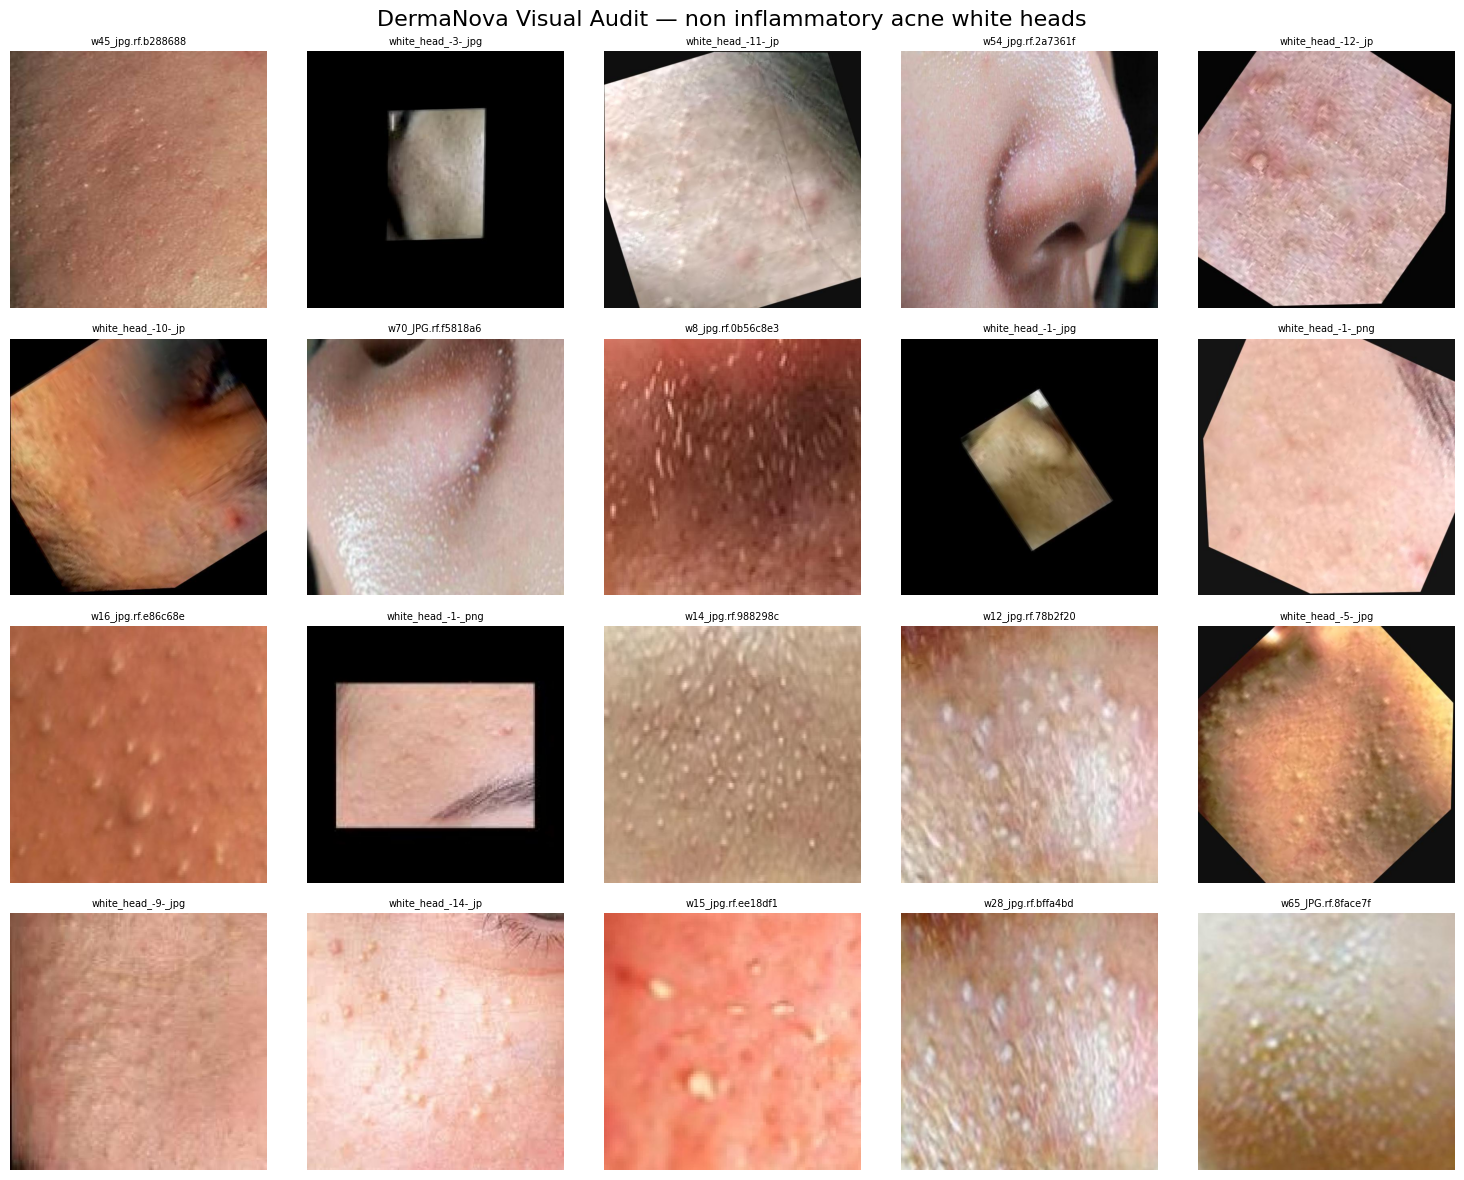

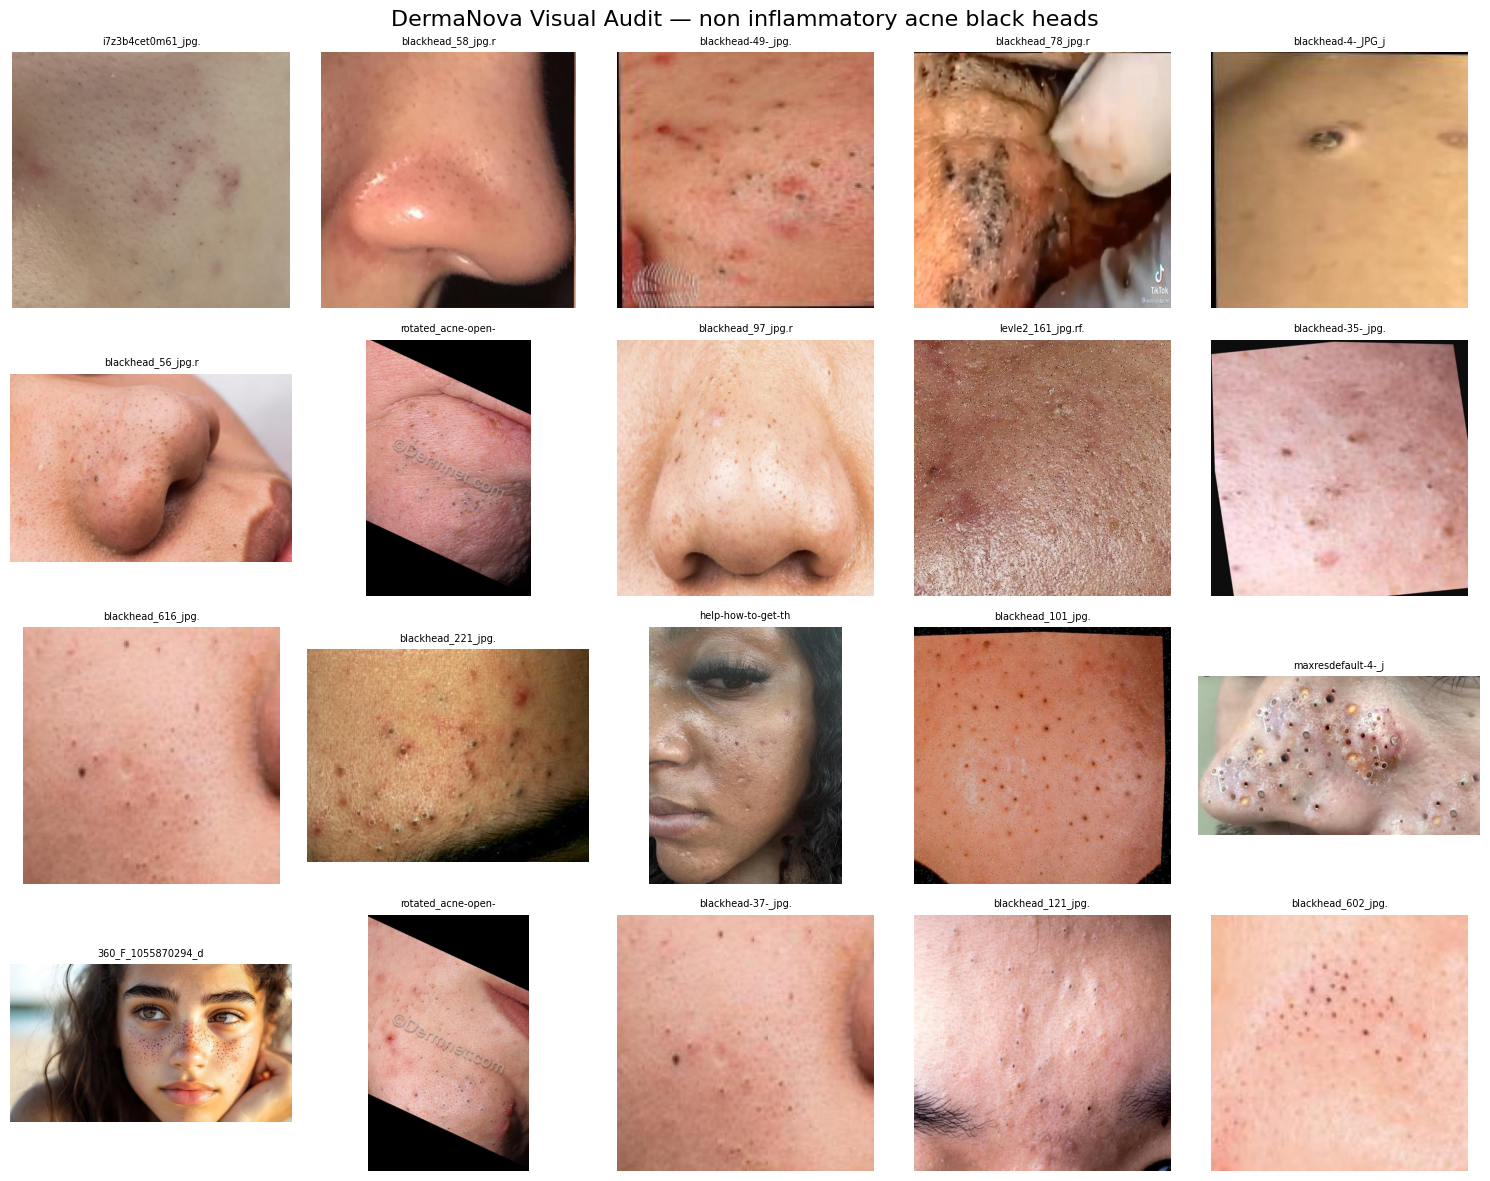

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

classes = [
    "non inflammatory acne white heads",
    "non inflammatory acne black heads",
    "inflammatory acne",
    "dark spots",
    "pigmentation",
    "Redness",
    "pores",
    "wrinkles"
]

random.seed(42)

for class_name in classes:

    class_dir = DATASET_DIR / class_name

    image_paths = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(
        image_paths,
        min(20, len(image_paths))
    )

    fig, axes = plt.subplots(4, 5, figsize=(15, 12))

    fig.suptitle(
        f"DermaNova Visual Audit — {class_name}",
        fontsize=16
    )

    for ax, image_path in zip(axes.flat, samples):

        try:
            img = Image.open(image_path).convert("RGB")

            ax.imshow(img)
            ax.set_title(image_path.name[:18], fontsize=7)
            ax.axis("off")

        except:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# Label Quality & Class Separability.

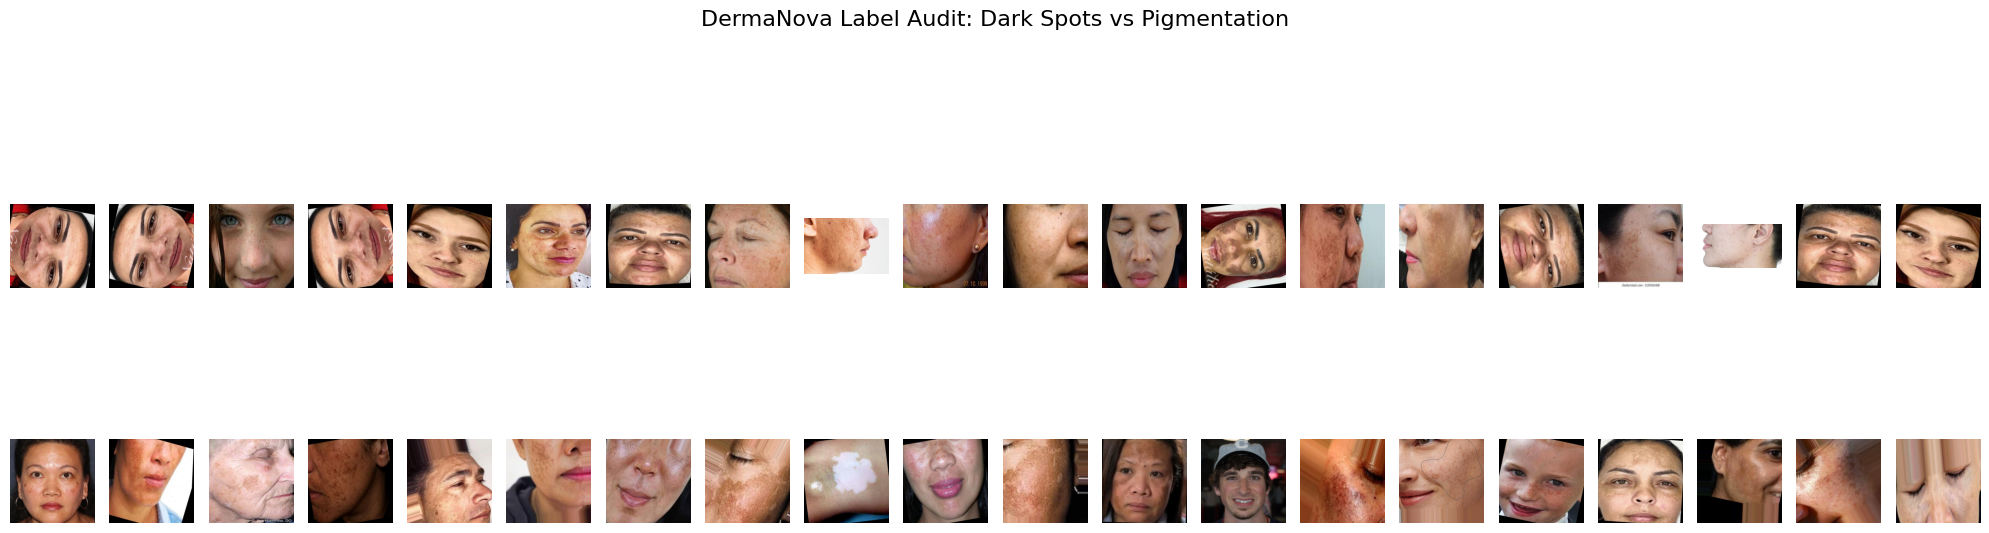

In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

random.seed(42)

classes_to_compare = [
    "dark spots",
    "pigmentation"
]

samples_per_class = 20

fig, axes = plt.subplots(
    2, samples_per_class,
    figsize=(20, 7)
)

for row, class_name in enumerate(classes_to_compare):

    class_dir = DATASET_DIR / class_name

    image_paths = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(
        image_paths,
        samples_per_class
    )

    for col, image_path in enumerate(samples):

        try:
            img = Image.open(image_path).convert("RGB")

            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_ylabel(
                    class_name,
                    fontsize=12
                )

        except:
            axes[row, col].axis("off")

plt.suptitle(
    "DermaNova Label Audit: Dark Spots vs Pigmentation",
    fontsize=16
)

plt.tight_layout()
plt.show()

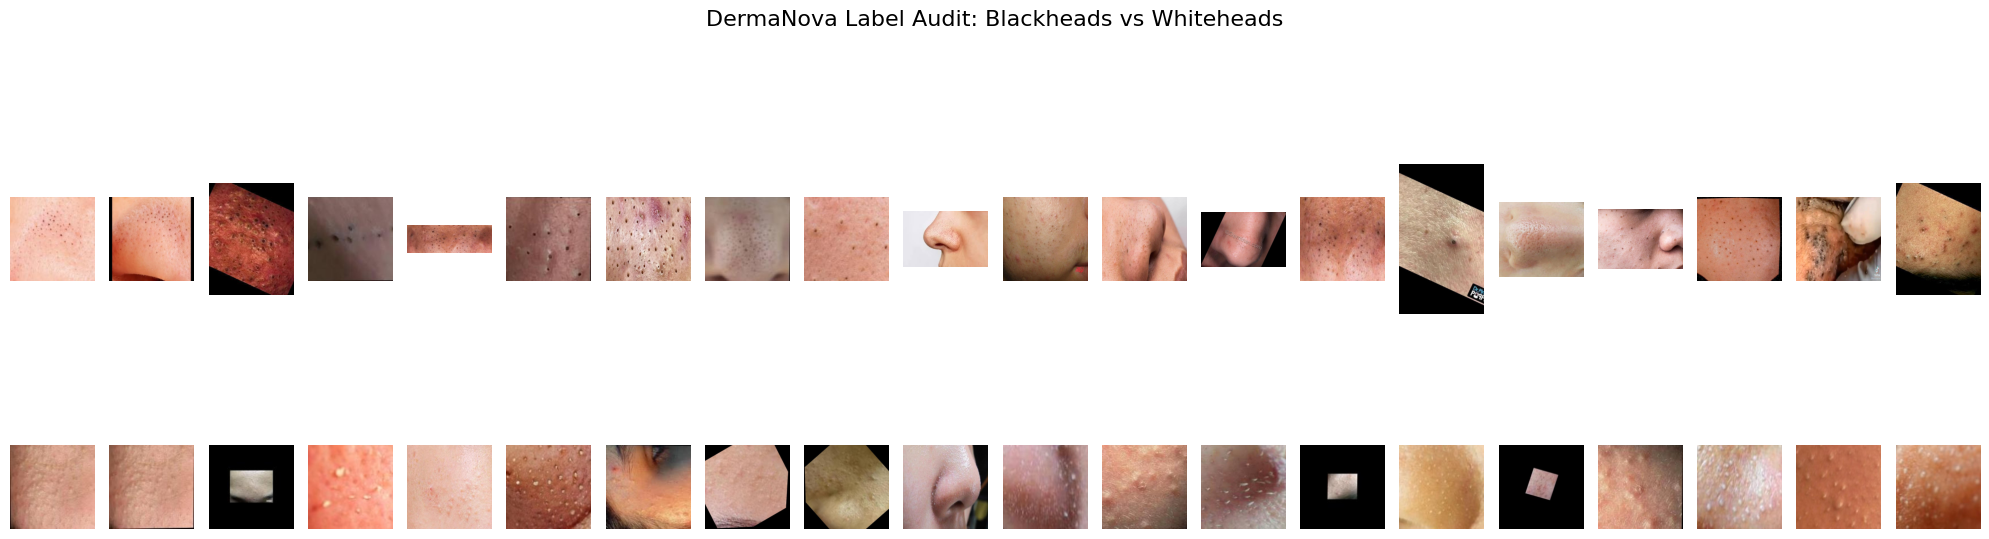

In [2]:
classes_to_compare = [
    "non inflammatory acne black heads",
    "non inflammatory acne white heads"
]

fig, axes = plt.subplots(
    2, 20,
    figsize=(20, 7)
)

for row, class_name in enumerate(classes_to_compare):

    class_dir = DATASET_DIR / class_name

    image_paths = [
        p for p in class_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(
        image_paths,
        min(20, len(image_paths))
    )

    for col, image_path in enumerate(samples):

        try:
            img = Image.open(image_path).convert("RGB")

            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_ylabel(
                    class_name,
                    fontsize=10
                )

        except:
            axes[row, col].axis("off")

plt.suptitle(
    "DermaNova Label Audit: Blackheads vs Whiteheads",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Build the Clean Dataset Pipeline

In [3]:
import pandas as pd
from pathlib import Path
from PIL import Image

DATASET_DIR = Path(
    "/kaggle/input/datasets/shijo96john/"
    "facial-skin-acne-pigmentation-pores-wrinkles/dataset"
)

records = []

for class_dir in DATASET_DIR.iterdir():

    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        try:
            with Image.open(image_path) as img:

                width, height = img.size

            records.append({
                "class": class_dir.name,
                "filename": image_path.name,
                "path": str(image_path),
                "width": width,
                "height": height,
                "aspect_ratio": round(width / height, 3),
                "format": image_path.suffix.lower()
            })

        except Exception:
            pass

df = pd.DataFrame(records)

print("Total images:", len(df))
print("\nImages per class:")
print(df["class"].value_counts())

print("\nImage dimensions:")
print(df[["width", "height"]].describe())

df.head()

Total images: 4233

Images per class:
class
dark spots                           619
inflammatory acne                    603
wrinkles                             600
Redness                              600
pores                                600
pigmentation                         599
non inflammatory acne black heads    312
non inflammatory acne white heads    300
Name: count, dtype: int64

Image dimensions:
             width       height
count  4233.000000  4233.000000
mean    710.324592   693.831325
std     317.381018   336.189870
min     150.000000   149.000000
25%     640.000000   640.000000
50%     640.000000   640.000000
75%     640.000000   640.000000
max    6900.000000  5312.000000


,class,filename,path,width,height,aspect_ratio,format
0,non inflammatory acne white heads,w45_jpg.rf.0ae39f7b979002e9c0f460e8d46dd48a.jpg,/kaggle/input/datasets/shijo96john/facial-skin...,640,640,1.0,.jpg
1,non inflammatory acne white heads,w47_jpg.rf.7337d0fda8ccb110e234c175189ddac3.jpg,/kaggle/input/datasets/shijo96john/facial-skin...,640,640,1.0,.jpg
2,non inflammatory acne white heads,white_head_-4-_jpg.rf.a6669711289fc117e520e0fd...,/kaggle/input/datasets/shijo96john/facial-skin...,640,640,1.0,.jpg
3,non inflammatory acne white heads,white_head_-9-_jpg.rf.461647d46bd848de11e24d70...,/kaggle/input/datasets/shijo96john/facial-skin...,640,640,1.0,.jpg
4,non inflammatory acne white heads,w37_jpg.rf.1b3f039c45732a7a38ab87d2e5530b05.jpg,/kaggle/input/datasets/shijo96john/facial-skin...,640,640,1.0,.jpg


In [4]:
df.to_csv(
    "/kaggle/working/dermanova_dataset_audit.csv",
    index=False
)

print("Audit report saved.")

Audit report saved.
